In [14]:
#basic packages: 
import xarray as xr
import numpy as np
import pandas as pd
import netCDF4

#colormaps: 
import cmocean.cm as cmo

#Matplotlib: 
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as ticker
import matplotlib.gridspec as gridspec
from matplotlib.colors import ListedColormap, LinearSegmentedColormap

#cartopy: 
import cartopy.crs as ccrs
from cartopy.io.shapereader import Reader
from cartopy.feature import ShapelyFeature
import cartopy.feature as cfeature
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

#RUCOOL maps: 
# import cool_maps.plot as cplt
import geopandas as gpd
import xarray as xr
from shapely import contains_xy
#geopandas: 
# import geopandas as gpd

## define font: 
hfont = {'fontname':'Helvetica'}
from erddapy import ERDDAP
import pandas as pd
import geopandas as gpd


/var/folders/r0/lj1737_n4td8q214ln70ctfh0000gn/T/ipykernel_42283/219623943.py:22: DeprecationWarning: The LONGITUDE_FORMATTER module-level attribute was deprecated in Cartopy 0.26. Use LongitudeFormatter instead.
  from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
/var/folders/r0/lj1737_n4td8q214ln70ctfh0000gn/T/ipykernel_42283/219623943.py:22: DeprecationWarning: The LATITUDE_FORMATTER module-level attribute was deprecated in Cartopy 0.26. Use LatitudeFormatter instead.
  from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER


## Doppio

In [2]:
url = "https://tds.marine.rutgers.edu/thredds/dodsC/roms/doppio/DopAnV3R3-ini2007_da/mon_avg"
ds = xr.open_dataset(url)

In [3]:
if ds.Vtransform == 1:
    Zo_rho = ds.hc * (ds.s_rho - ds.Cs_r) + ds.Cs_r * ds.h
    z_rho = Zo_rho + ds.zeta * (1 + Zo_rho / ds.h)
elif ds.Vtransform == 2:
    Zo_rho = (ds.hc * ds.s_rho + ds.Cs_r * ds.h) / (ds.hc + ds.h)
    z_rho = ds.zeta + (ds.zeta + ds.h) * Zo_rho


# add depth dimension back into dataset: 
ds['z_rho']=z_rho.transpose("ocean_time", "s_rho", "eta_rho", "xi_rho")

In [5]:
ds

<xarray.Dataset> Size: 11GB
Dimensions:      (s_rho: 40, s_w: 41, eta_rho: 106, xi_rho: 242, eta_u: 106,
                  xi_u: 241, eta_v: 105, xi_v: 242, eta_psi: 105, xi_psi: 241,
                  ocean_time: 216)
Coordinates:
  * s_rho        (s_rho) float64 320B -0.9875 -0.9625 ... -0.0375 -0.0125
  * s_w          (s_w) float64 328B -1.0 -0.975 -0.95 ... -0.05 -0.025 0.0
    lon_rho      (eta_rho, xi_rho) float64 205kB ...
    lat_rho      (eta_rho, xi_rho) float64 205kB ...
    lon_u        (eta_u, xi_u) float64 204kB ...
    lat_u        (eta_u, xi_u) float64 204kB ...
    lon_v        (eta_v, xi_v) float64 203kB ...
    lat_v        (eta_v, xi_v) float64 203kB ...
    lon_psi      (eta_psi, xi_psi) float64 202kB ...
    lat_psi      (eta_psi, xi_psi) float64 202kB ...
  * ocean_time   (ocean_time) datetime64[ns] 2kB 2007-01-17 ... 2024-12-16
Dimensions without coordinates: eta_rho, xi_rho, eta_u, xi_u, eta_v, xi_v,
                                eta_psi, xi_psi
Data variables: (12/34)
    spherical    int32 4B ...
    xl           float64 8B ...
    el           float64 8B ...
    Vtransform   int32 4B 2
    Vstretching  int32 4B ...
    theta_s      float64 8B ...
    ...           ...
    shflux       (ocean_time, eta_rho, xi_rho) float64 44MB ...
    ssflux       (ocean_time, eta_rho, xi_rho) float64 44MB ...
    swrad_daily  (ocean_time, eta_rho, xi_rho) float64 44MB ...
    sustr        (ocean_time, eta_u, xi_u) float64 44MB ...
    svstr        (ocean_time, eta_v, xi_v) float64 44MB ...
    z_rho        (ocean_time, s_rho, eta_rho, xi_rho) float64 2GB -3.838e+03 ...
Attributes:
    title:                   DopAnV3R3-ini2007 - ROMS DOPPIO 7km reanalysis (...
    summary:                 doppio
    EXTRA_DIMENSION.tracer:  2

In [4]:
#subset dataset to be just temperatuere - it will keep all coords and dims
variables = ['temp','z_rho','h']
ds_sub=ds[variables]
ds_sub


<xarray.Dataset> Size: 4GB
Dimensions:     (ocean_time: 216, s_rho: 40, eta_rho: 106, xi_rho: 242)
Coordinates:
  * ocean_time  (ocean_time) datetime64[ns] 2kB 2007-01-17 ... 2024-12-16
  * s_rho       (s_rho) float64 320B -0.9875 -0.9625 -0.9375 ... -0.0375 -0.0125
    lon_rho     (eta_rho, xi_rho) float64 205kB ...
    lat_rho     (eta_rho, xi_rho) float64 205kB ...
Dimensions without coordinates: eta_rho, xi_rho
Data variables:
    temp        (ocean_time, s_rho, eta_rho, xi_rho) float64 2GB ...
    z_rho       (ocean_time, s_rho, eta_rho, xi_rho) float64 2GB -3.838e+03 ....
    h           (eta_rho, xi_rho) float64 205kB ...
Attributes:
    title:                   DopAnV3R3-ini2007 - ROMS DOPPIO 7km reanalysis (...
    summary:                 doppio
    EXTRA_DIMENSION.tracer:  2

In [5]:
bottom=ds_sub.isel(s_rho=[0])

In [6]:
bottom_cut = bottom.isel(xi_rho=slice(0, 150))

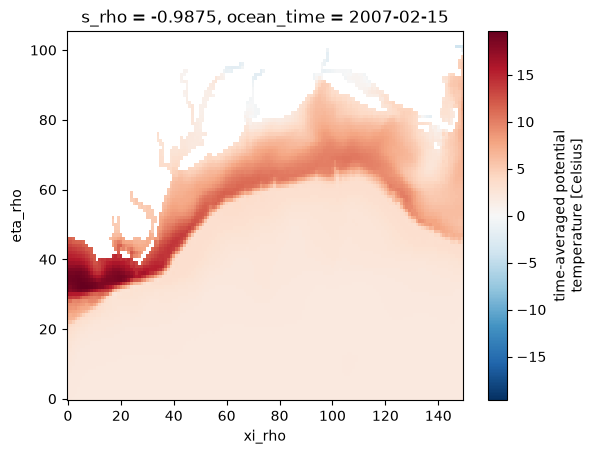

In [7]:
bottom_cut.temp.isel(ocean_time=1).plot()

In [8]:
gdf = gpd.read_file("/Users/becca/Library/CloudStorage/Dropbox/Thesis/FishBot/fishbotshapefiles.shp")
gdf = gdf.set_crs("EPSG:4326")

poly = gdf.geometry.union_all()

inside = contains_xy(poly, bottom_cut.lon_rho.values, bottom_cut.lat_rho.values)
mask = xr.DataArray(inside, dims=bottom_cut.lon_rho.dims, coords=bottom_cut.lon_rho.coords)

print(mask.sum().item())  # should be > 0

clipped = bottom_cut.where(mask, drop=True)

2585


In [24]:
print(gdf)

       area    Region                                           geometry
0  5.770158       MAB  POLYGON ((-74.71113 36.50517, -74.71232 36.501...
1  6.227196       SNE  POLYGON ((-73.20656 40.61663, -73.20523 40.617...
2  4.762347        GB  POLYGON ((-66.74085 40.75303, -66.74573 40.750...
3  4.382310  GOM_West  POLYGON ((-69.91489 42.02679, -69.98377 42.004...
4  6.376634  GOM_East  POLYGON ((-65.56925 42.16613, -65.68762 41.935...


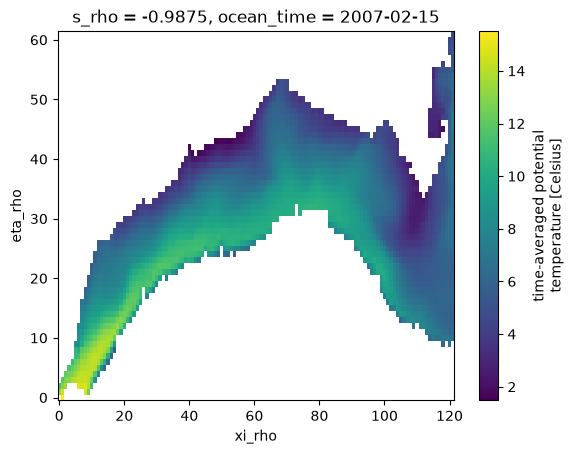

In [20]:
clipped.temp.isel(ocean_time=1).plot()

In [9]:
import xarray as xr
from shapely import contains_xy

lon = bottom_cut.lon_rho.values
lat = bottom_cut.lat_rho.values
bottom_cut = bottom_cut.assign_coords(month=bottom_cut.ocean_time.dt.month)
masks = []
for name, geom in zip(gdf["Region"], gdf.geometry):
    inside = contains_xy(geom, lon, lat)
    masks.append(xr.DataArray(inside, dims=bottom_cut.lon_rho.dims, coords=bottom_cut.lon_rho.coords))

region_mask = xr.concat(masks, dim=xr.DataArray(gdf["Region"].values, dims="Region", name="Region"))

print(region_mask.sum(dim=("eta_rho", "xi_rho")).to_series())  # cells per region

Region
MAB         1144
SNE         1194
GB           137
GOM_West     110
GOM_East       0
dtype: int64


In [10]:
regional_mean = bottom_cut["temp"].where(region_mask).mean(dim=("eta_rho", "xi_rho"))
# dims: (Region, ocean_time, s_rho)

In [33]:
regional_mean

<xarray.DataArray 'temp' (ocean_time: 216, s_rho: 1, Region: 5)> Size: 9kB
array([[[11.0577963 ,  9.23335002,  7.93009975,  6.64442897,
                 nan]],

       [[ 8.02057419,  6.50041593,  6.06820558,  4.81285336,
                 nan]],

       [[ 7.04121482,  5.35078896,  4.6798558 ,  4.16666201,
                 nan]],

       ...,

       [[16.8176441 , 13.40009495, 10.39978815,  9.49796648,
                 nan]],

       [[15.94449646, 13.2330175 ,  9.92110601,  9.33184704,
                 nan]],

       [[12.28761056, 11.23169811,  8.46864973,  8.21810859,
                 nan]]], shape=(216, 1, 5))
Coordinates:
  * ocean_time  (ocean_time) datetime64[ns] 2kB 2007-01-17 ... 2024-12-16
    month       (ocean_time) int64 2kB 1 2 3 4 5 6 7 8 9 ... 5 6 7 8 9 10 11 12
  * s_rho       (s_rho) float64 8B -0.9875
  * Region      (Region) object 40B 'MAB' 'SNE' 'GB' 'GOM_West' 'GOM_East'
Attributes:
    long_name:      time-averaged potential temperature
    units:          Celsius
    time:           ocean_time
    field:          temperature, scalar, series
    standard_name:  sea_water_potential_temperature

In [11]:
regional_mean.sel(Region="MAB").groupby("month")  # replace "RegionName" with the actual region name you want to select

<DataArrayGroupBy, grouped over 1 grouper(s), 12 groups in total:
    'month': UniqueGrouper('month'), 12/12 groups with labels 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12>

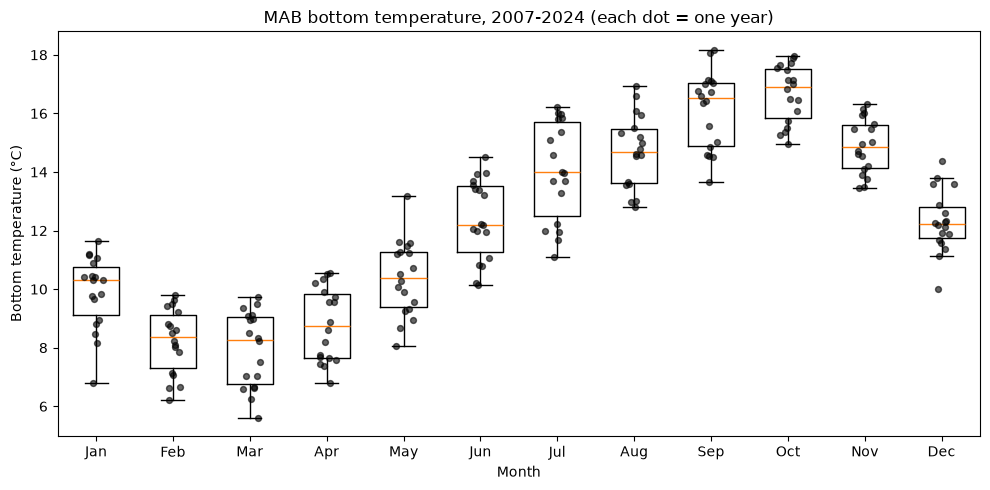

In [12]:
g = regional_mean.sel(Region="MAB")
if "s_rho" in g.dims:
    g = g.isel(s_rho=0)  # bottom layer; skip if already selected

months, data = zip(*[(m, grp.values) for m, grp in g.groupby("month")])

fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot(data, positions=months, widths=0.6, showfliers=False)

rng = np.random.default_rng(0)
for m, y in zip(months, data):
    ax.scatter(rng.normal(m, 0.07, len(y)), y, s=18, alpha=0.6, color="k", zorder=3)

ax.set_xticks(list(months))
ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_xlabel("Month")
ax.set_ylabel("Bottom temperature (°C)")
ax.set_title("MAB bottom temperature, 2007-2024 (each dot = one year)")
plt.tight_layout()
plt.show()

## Fishbot

In [15]:
def truncate_at_first_space(col_name):
    return col_name.split(' ')[0]
server = 'https://erddap.ondeckdata.com/erddap/'
e = ERDDAP(
    server=server,
    protocol="tabledap",
    response="nc",
)
e.dataset_id = 'fishbot_realtime'
#* variables are an optional parameter that can be specified to limit the data retrieved from the ERDDAP server.
#* if unspecified, all available variables will be retrieved.
e.variables = [
    "time", "latitude", "longitude", "grid_id", "depth",
    "temperature", "temperature_count",
    # "dissolved_oxygen", "dissolved_oxygen_count",
    # "salinity", "salinity_count",
    "data_provider", "stat_area", "fishery_dependent",
]
START = "2007-01-01"
END = "2024-12-31"
start = pd.to_datetime(START, utc=True)
end = pd.to_datetime(END, utc=True)

#* constraints are used to filter the data retrieved from the ERDDAP server based on specific conditions.
#* without constraints, all available data within the specified time range will be retrieved.
e.constraints = {
    "time>=": start.isoformat(),
    "time<": end.isoformat(),
    # "latitude>=": 40.0,
    # "latitude<=": 42.0,
    # "longitude>=": -72.0,
    # "longitude<=": -69.0,
    # "stat_area=": 539,
    # "fishery_dependent=": 1,  # 1 = dependent; 0 = independent.
    # "data_provider=~": ".*CFRF.*",  # Includes combined provider labels.
}

df = e.to_pandas()
df.rename(columns=lambda x: truncate_at_first_space(x), inplace=True)
df['time'] = pd.to_datetime(df['time'])
df['data_provider'] = df['data_provider'].str.replace(',', '')
df['data_providers_adjusted'] = df['data_provider'].apply(lambda x: x.split(' ')[0] if ' ' in x else x)
df

,time,latitude,longitude,grid_id,depth,temperature,temperature_count,data_provider,stat_area,fishery_dependent,data_providers_adjusted
0,2007-01-01 00:00:00+00:00,42.630730,-68.446050,21451,205,8.306190,7,StudyFleet,515,1,StudyFleet
1,2007-01-01 00:00:00+00:00,42.567690,-68.446610,21452,213,8.340260,9,StudyFleet,515,1,StudyFleet
2,2007-01-01 00:00:00+00:00,42.568073,-68.531890,21278,214,8.373212,7,StudyFleet,515,1,StudyFleet
3,2007-01-01 00:00:00+00:00,42.631428,-68.616790,21103,197,8.400000,1,StudyFleet,515,1,StudyFleet
4,2007-01-01 00:00:00+00:00,42.505035,-68.532364,21279,210,8.383026,4,StudyFleet,515,1,StudyFleet
...,...,...,...,...,...,...,...,...,...,...,...
167865,2024-12-30 00:00:00+00:00,41.094402,-71.376370,15385,39,9.632292,96,CFRF,539,0,CFRF
167866,2024-12-30 00:00:00+00:00,42.304886,-70.657070,16932,47,7.653099,48,eMOLT,514,1,eMOLT
167867,2024-12-30 00:00:00+00:00,44.016365,-68.258650,21777,94,6.264278,24,eMOLT,512,1,eMOLT
167868,2024-12-30 00:00:00+00:00,40.341550,-71.184920,15745,85,10.137910,24,eMOLT,537,1,eMOLT


In [17]:
stat_areas = gpd.read_file("fishbotshapefiles.shp")

/opt/anaconda3/envs/fishbot/lib/python3.14/site-packages/cartopy/mpl/feature_artist.py:142: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '
/opt/anaconda3/envs/fishbot/lib/python3.14/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/opt/anaconda3/envs/fishbot/lib/python3.14/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/opt/anaconda3/envs/fishbot/lib/python3.14/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/opt/anaconda3/envs/fishbot/lib/python3.14/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/opt/anaconda3/envs/fishbot/lib/python3.14/site-packages/shapely/constructive.py:246: Ru

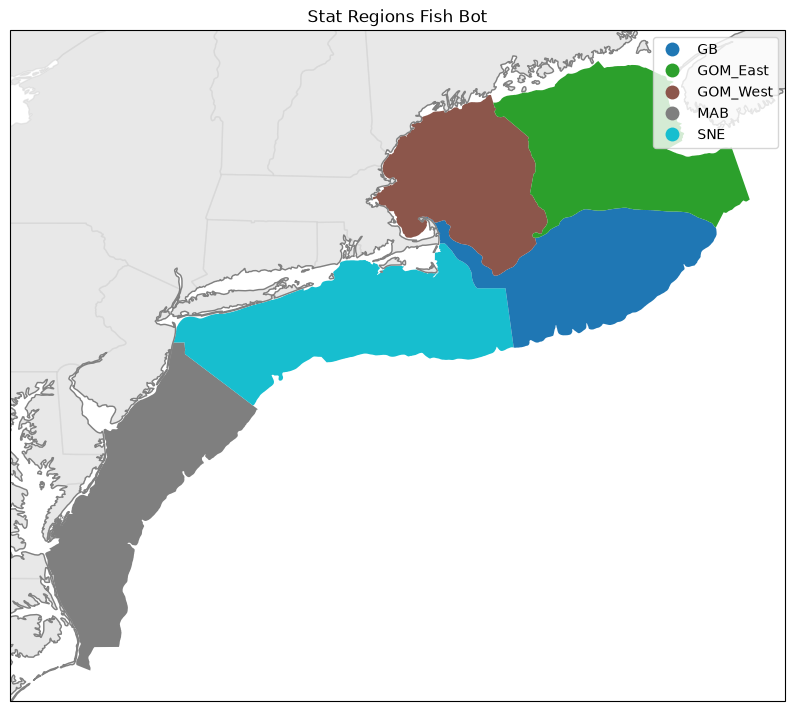

In [18]:
## Wow look at those areas
fig,ax = plt.subplots(figsize=(10, 10), subplot_kw={'projection': ccrs.PlateCarree()})

stat_areas.plot(
    column="Region",   # color by division
    legend=True,
    ax=ax
)
ax.add_feature(cfeature.STATES, color="lightgrey", alpha=0.5)
ax.add_feature(cfeature.COASTLINE,color='grey');
ax.set_title("Stat Regions Fish Bot")
plt.show()

In [20]:
# 1. Load the regions
regions = gpd.read_file("fishbotshapefiles.shp")
regions = regions.set_crs("EPSG:4326")

# 2. Turn your DataFrame into a GeoDataFrame
#    (adjust column names and CRS to match your data; 4326 = lon/lat WGS84)
points = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df["longitude"], df["latitude"]),
    crs="EPSG:4326",
)

# 3. Make sure both use the same CRS
points = points.to_crs(regions.crs)

# 4. Pick one region (use whatever column identifies them)
print(regions.columns)          # find the name column
region = regions[regions["Region"] == "MAB"]

# 5a. Points within that region
subset = points[points.within(region.geometry.iloc[0])]

# 5b. Or, if the region has multiple polygon parts / you want a join:
subset = gpd.sjoin(points, region, predicate="within", how="inner")

Index(['area', 'Region', 'geometry'], dtype='str')


/opt/anaconda3/envs/fishbot/lib/python3.14/site-packages/cartopy/mpl/feature_artist.py:142: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


/opt/anaconda3/envs/fishbot/lib/python3.14/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/opt/anaconda3/envs/fishbot/lib/python3.14/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/opt/anaconda3/envs/fishbot/lib/python3.14/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/opt/anaconda3/envs/fishbot/lib/python3.14/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/opt/anaconda3/envs/fishbot/lib/python3.14/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/opt/anaconda3/envs/fishbot/lib/python3.14/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects

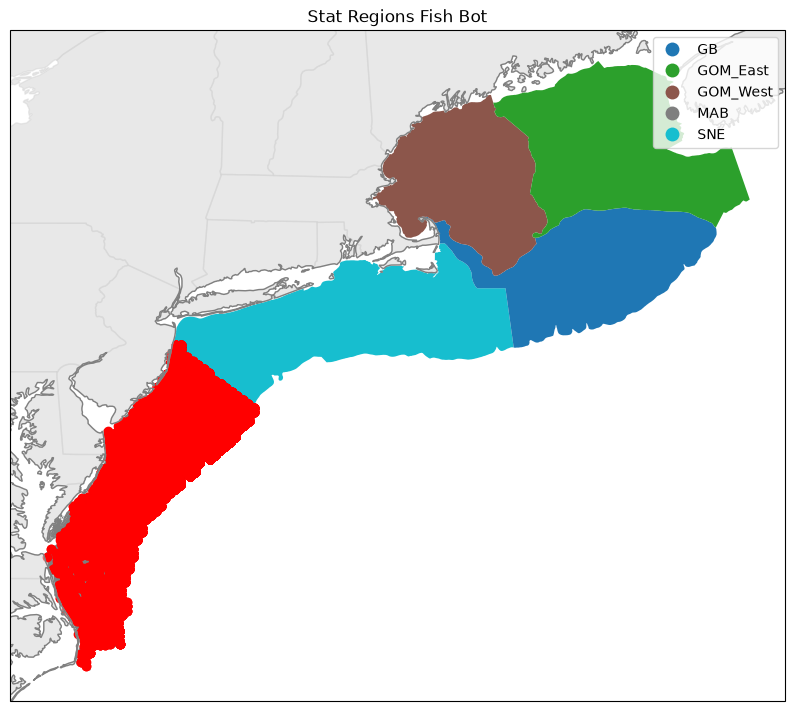

In [21]:
fig,ax = plt.subplots(figsize=(10, 10), subplot_kw={'projection': ccrs.PlateCarree()})

stat_areas.plot(
    column="Region",   # color by division
    legend=True,
    ax=ax
)
ax.add_feature(cfeature.STATES, color="lightgrey", alpha=0.5)
ax.add_feature(cfeature.COASTLINE,color='grey');
ax.set_title("Stat Regions Fish Bot")
plt.scatter(subset.longitude,subset.latitude,color='red')

In [22]:
subset['month'] = pd.to_datetime(subset.time).dt.month
subset['year'] = pd.to_datetime(subset.time).dt.year

In [23]:
month_temp = subset.groupby(['month'])

<Axes: title={'center': 'temperature'}, xlabel='month'>

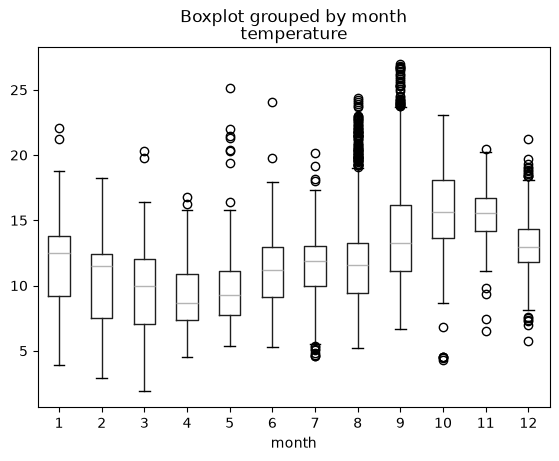

In [24]:
subset.boxplot(column = "temperature", by='month',grid=False)

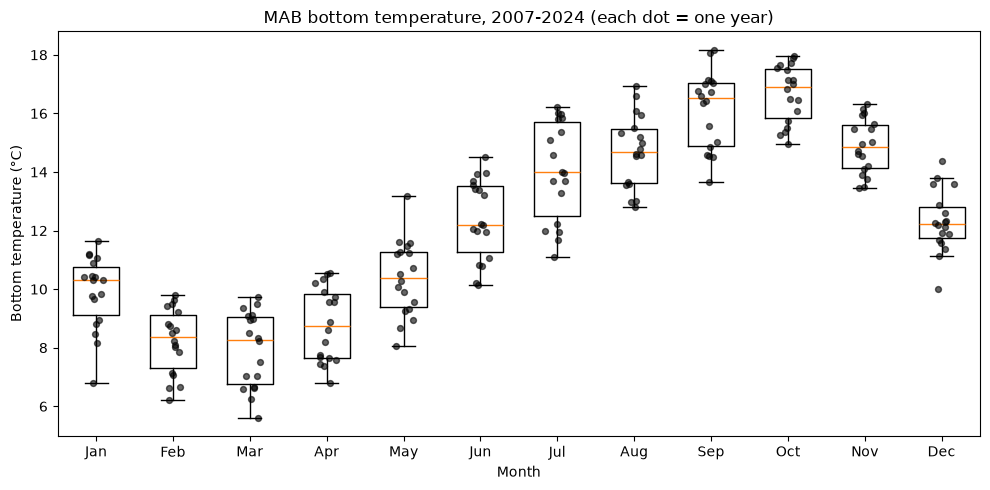

In [25]:
g = regional_mean.sel(Region="MAB")
if "s_rho" in g.dims:
    g = g.isel(s_rho=0)  # bottom layer; skip if already selected

months, data = zip(*[(m, grp.values) for m, grp in g.groupby("month")])

fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot(data, positions=months, widths=0.6, showfliers=False)

rng = np.random.default_rng(0)
for m, y in zip(months, data):
    ax.scatter(rng.normal(m, 0.07, len(y)), y, s=18, alpha=0.6, color="k", zorder=3)

ax.set_xticks(list(months))
ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_xlabel("Month")
ax.set_ylabel("Bottom temperature (°C)")
ax.set_title("MAB bottom temperature, 2007-2024 (each dot = one year)")
plt.tight_layout()
plt.show()

## Both Fishbot and Doppio data for the MAB region

Doppio years: [np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]
FishBot years: [np.int32(2007), np.int32(2008), np.int32(2009), np.int32(2010), np.int32(2011), np.int32(2012), np.int32(2013), np.int32(2014), np.int32(2015), np.int32(2016), np.int32(2017), np.int32(2018), np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024)]


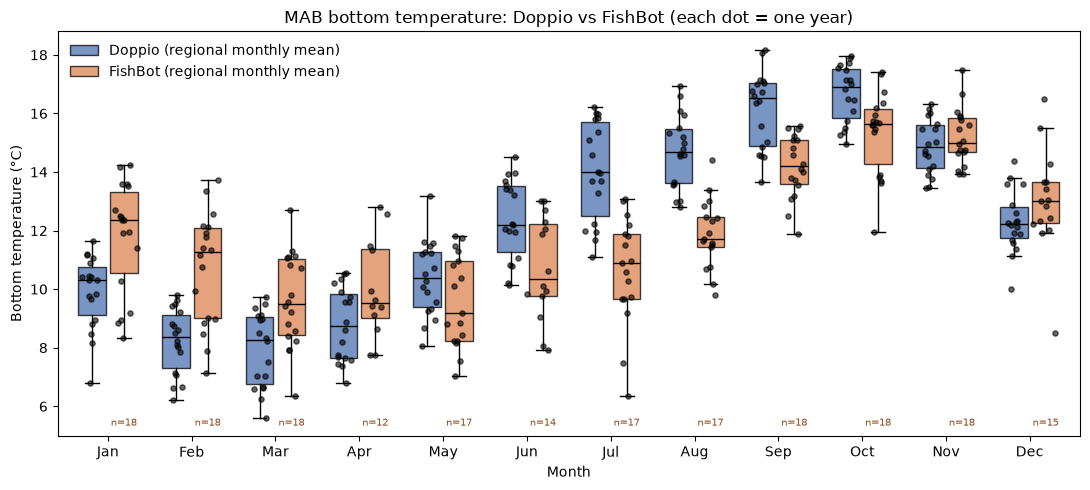

In [26]:
MATCH_YEARS = True   # restrict Doppio to the years FishBot actually covers

# --- FishBot: collapse observations to one regional mean per year-month ---
fb_ym = (subset.dropna(subset=["temperature"])
               .groupby(["year", "month"])["temperature"].mean().reset_index())
fish_months = sorted(fb_ym["month"].unique())
fish_data   = [fb_ym.loc[fb_ym["month"] == m, "temperature"].values for m in fish_months]
fish_years  = np.sort(fb_ym["year"].unique())

# --- Doppio: already one regional mean per year-month ---
g = regional_mean.sel(Region="MAB")
if "s_rho" in g.dims:
    g = g.isel(s_rho=0)
g = g.assign_coords(month=g.ocean_time.dt.month, year=g.ocean_time.dt.year)
if MATCH_YEARS:
    g = g.where(g.year.isin(fish_years), drop=True)

doppio_months, doppio_data = zip(*[(m, grp.values) for m, grp in g.groupby("month")])

print("Doppio years:", sorted(set(np.atleast_1d(g.year.values))))
print("FishBot years:", list(fish_years))

# --- plot ---
off, w = 0.19, 0.33
fig, ax = plt.subplots(figsize=(11, 5))
bp_d = ax.boxplot(list(doppio_data), positions=[m - off for m in doppio_months],
                  widths=w, showfliers=False, patch_artist=True, medianprops=dict(color="k"))
bp_f = ax.boxplot(fish_data, positions=[m + off for m in fish_months],
                  widths=w, showfliers=False, patch_artist=True, medianprops=dict(color="k"))
for b in bp_d["boxes"]:
    b.set_facecolor("#4C72B0"); b.set_alpha(0.75)
for b in bp_f["boxes"]:
    b.set_facecolor("#DD8452"); b.set_alpha(0.75)

rng = np.random.default_rng(0)
for pos, series in [(-off, zip(doppio_months, doppio_data)), (off, zip(fish_months, fish_data))]:
    for m, y in series:
        ax.scatter(rng.normal(m + pos, 0.05, len(y)), y, s=14, alpha=0.6, color="k", zorder=3)

ymin, ymax = ax.get_ylim()
for m, y in zip(fish_months, fish_data):
    ax.text(m + off, ymin + 0.02*(ymax - ymin), f"n={len(y)}",
            ha="center", va="bottom", fontsize=7, color="#8a4a22")

ax.set_xlim(0.4, 12.6)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_xlabel("Month")
ax.set_ylabel("Bottom temperature (°C)")
ax.set_title("MAB bottom temperature: Doppio vs FishBot (each dot = one year)")
ax.legend([bp_d["boxes"][0], bp_f["boxes"][0]],
          ["Doppio (regional monthly mean)", "FishBot (regional monthly mean)"],
          frameon=False, loc="upper left")
fig.tight_layout()
plt.show()

200 paired year-months, 2007-2024
       count    median
month                 
1         18  2.371707
2         18  3.025090
3         18  1.571612
4         12  0.844269
5         17 -0.600177
6         14 -2.029723
7         17 -3.137267
8         17 -3.104234
9         18 -1.514428
10        18 -1.344614
11        18 -0.025439
12        15  0.142606


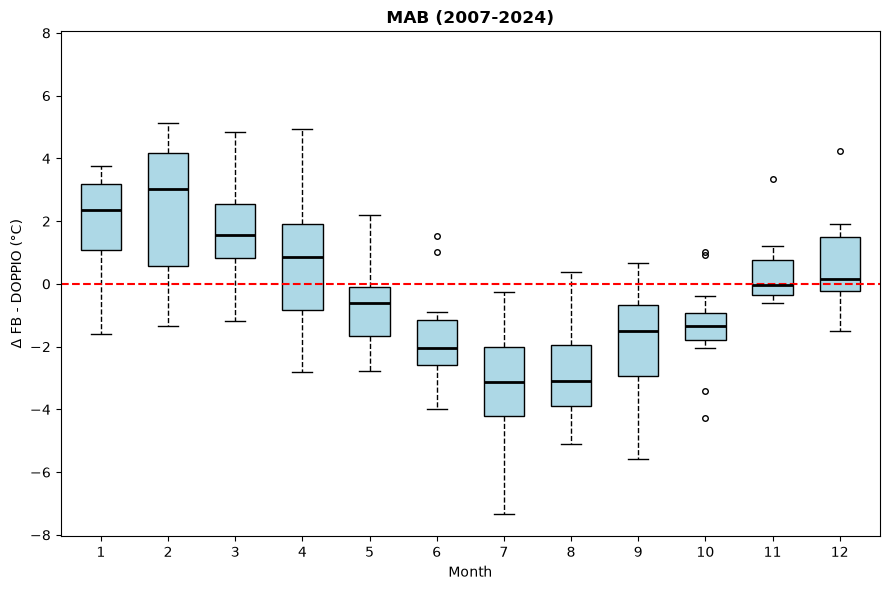

In [27]:
REGION = "MAB"   # the example used SNE; change cell 23's sjoin region to match if you switch

# --- Doppio: regional monthly mean, as a flat table ---
g = regional_mean.sel(Region=REGION)
if "s_rho" in g.dims:
    g = g.isel(s_rho=0)
g = g.assign_coords(month=g.ocean_time.dt.month, year=g.ocean_time.dt.year)
doppio_ym = pd.DataFrame({"year": g.year.values,
                          "month": g.month.values,
                          "doppio": np.asarray(g.values).ravel()})

# --- FishBot: regional monthly mean ---
fb_ym = (subset.dropna(subset=["temperature"])
               .groupby(["year", "month"])["temperature"].mean().reset_index()
               .rename(columns={"temperature": "fishbot"}))

# --- pair by year-month and difference ---
both = fb_ym.merge(doppio_ym, on=["year", "month"], how="inner")
both["delta"] = both["fishbot"] - both["doppio"]
print(f"{len(both)} paired year-months, {both.year.min()}-{both.year.max()}")
print(both.groupby("month")["delta"].agg(["count", "median"]))

months = sorted(both["month"].unique())
data   = [both.loc[both["month"] == m, "delta"].values for m in months]

# --- plot ---
fig, ax = plt.subplots(figsize=(9, 6))
ax.boxplot(data, positions=months, widths=0.6, patch_artist=True,
           medianprops=dict(color="k", linewidth=2),
           boxprops=dict(facecolor="lightblue", edgecolor="k"),
           whiskerprops=dict(linestyle="--", color="k"),
           capprops=dict(color="k"),
           flierprops=dict(marker="o", markersize=4,
                           markerfacecolor="none", markeredgecolor="k"))
ax.axhline(0, color="red", linestyle="--", linewidth=1.5)

ax.set_xlim(0.4, 12.6)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(range(1, 13))
ax.set_xlabel("Month")
ax.set_ylabel("Δ FB - DOPPIO (°C)")
ax.set_title(f"{REGION} ({both.year.min()}-{both.year.max()})", fontweight="bold")
lim = np.abs(both["delta"]).max() * 1.1
ax.set_ylim(-lim, lim)
fig.tight_layout()
plt.show()

200 paired year-months, 2007-2024
       count    median
month                 
1         18  2.371707
2         18  3.025090
3         18  1.571612
4         12  0.844269
5         17 -0.600177
6         14 -2.029723
7         17 -3.137267
8         17 -3.104234
9         18 -1.514428
10        18 -1.344614
11        18 -0.025439
12        15  0.142606


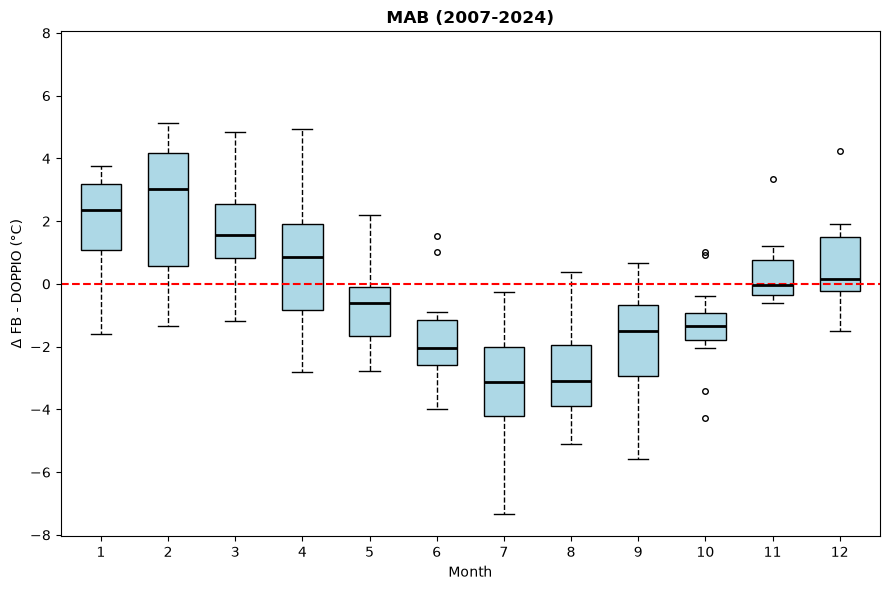

In [28]:
REGION = "MAB"   # the example used SNE; change cell 23's sjoin region to match if you switch

# --- Doppio: regional monthly mean, as a flat table ---
g = regional_mean.sel(Region=REGION)
if "s_rho" in g.dims:
    g = g.isel(s_rho=0)
g = g.assign_coords(month=g.ocean_time.dt.month, year=g.ocean_time.dt.year)
doppio_ym = pd.DataFrame({"year": g.year.values,
                          "month": g.month.values,
                          "doppio": np.asarray(g.values).ravel()})

# --- FishBot: regional monthly mean ---
fb_ym = (subset.dropna(subset=["temperature"])
               .groupby(["year", "month"])["temperature"].mean().reset_index()
               .rename(columns={"temperature": "fishbot"}))

# --- pair by year-month and difference ---
both = fb_ym.merge(doppio_ym, on=["year", "month"], how="inner")
both["delta"] = both["fishbot"] - both["doppio"]
print(f"{len(both)} paired year-months, {both.year.min()}-{both.year.max()}")
print(both.groupby("month")["delta"].agg(["count", "median"]))

months = sorted(both["month"].unique())
data   = [both.loc[both["month"] == m, "delta"].values for m in months]

# --- plot ---
fig, ax = plt.subplots(figsize=(9, 6))
ax.boxplot(data, positions=months, widths=0.6, patch_artist=True,
           medianprops=dict(color="k", linewidth=2),
           boxprops=dict(facecolor="lightblue", edgecolor="k"),
           whiskerprops=dict(linestyle="--", color="k"),
           capprops=dict(color="k"),
           flierprops=dict(marker="o", markersize=4,
                           markerfacecolor="none", markeredgecolor="k"))
ax.axhline(0, color="red", linestyle="--", linewidth=1.5)

ax.set_xlim(0.4, 12.6)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(range(1, 13))
ax.set_xlabel("Month")
ax.set_ylabel("Δ FB - DOPPIO (°C)")
ax.set_title(f"{REGION} ({both.year.min()}-{both.year.max()})", fontweight="bold")
lim = np.abs(both["delta"]).max() * 1.1
ax.set_ylim(-lim, lim)
fig.tight_layout()
plt.show()